# Project

In this project we will investigate the method of Physical Informed Weak Regression PIWR. The worked case is the Measles seasonally forced SEI model

In [10]:
# Import relevant parameters
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

In [60]:
# Define the Measle SEI model
def MeasleSEIModel(t, x, p):
    # p = [Xi1, Xi2, epsilon1, epsilon2, rho, theta, alfa, gamma]
    # x = states [S, E, I]
    
    Xi1 = p[0]
    Xi2 = p[1]
    epsilon1 = p[2]
    epsilon2 = p[3]
    rho = p[4]
    theta = p[5]
    alfa = p[6]
    gamma = p[7]
    N = p[8]
        
    S, En, Ei, Ci, I, Q, U, V = x
    
    phi = I/S
    beta = 10 * gamma /(phi * N)
    
    
    dS = Xi1*(1-epsilon1)*Ci - beta*(phi+rho-phi*rho)*S*I
    dEn = beta*phi*(1-rho)*S*I - alfa*En
    dEi = beta*phi*rho*S*I - (Xi1*epsilon2+alfa*(1-epsilon2))*Ei
    dCi = beta*rho*(1-phi)*S*I - Xi1*Ci
    dI = alfa*(1-theta)*En - (theta+gamma)*I
    dQ = alfa*(1-epsilon2)*Ei + theta*(alfa*En+I) - Xi2*Q
    dU = gamma*I + Xi2*Q
    dV = Xi1*(epsilon2*Ei + epsilon1*Ci)
    
    dxdt = np.array([dS, dEn, dEi, dCi, dI, dQ, dU, dV])

    return dxdt

In [61]:
""" Define interval and parameters for testing """

# The model is tested on 50 data points over 10 years.
t0 = 0
tf = 100 # Days
tspan = [t0,tf]
m = 5000 # Samples
t = np.linspace(t0,tf,m)


N = 7100 # Population size
p = [0.06, 0.04, 0.975, 0.3, 0.975, 0.95, 0.0685, 0.116, N]

x0 = [7000, 0, 0, 0, 100, 0, 0, 0]

sol = solve_ivp(MeasleSEIModel, tspan, x0, method = "BDF", t_eval = t, args = (p,))

S, En, Ei, Ci, I, Q, U, V = sol.y
t = sol.t


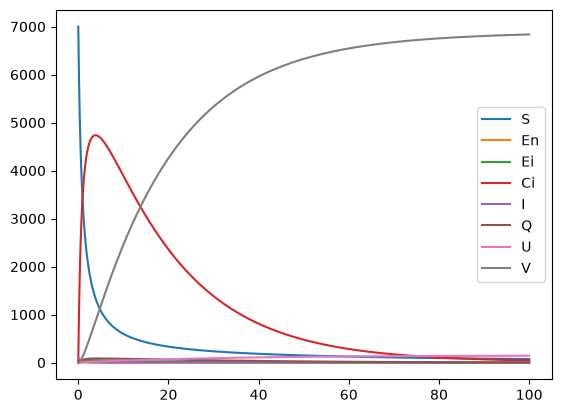

In [62]:
# Plot solution
plt.plot(t, S, label = "S")
plt.plot(t, En, label = "En")
plt.plot(t, Ei, label = "Ei")
plt.plot(t, Ci, label = "Ci")
plt.plot(t, I, label = "I")
plt.plot(t, Q, label = "Q")
plt.plot(t, U, label = "U")
plt.plot(t, V, label = "V")
plt.legend()
plt.show()

Setting up the PIWR solution for the generated model:

$\boldsymbol{\dot{x}} = f_0(\boldsymbol{x}, t) + A(\boldsymbol{x},t)\boldsymbol{\theta}$

In [ ]:
A = np.array([Ci, -Ci, ])